# Initialize Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Read CSV Files

In [2]:
customers = pd.read_csv("Datasets/customers.csv")
order_items = pd.read_csv("Datasets/order_items.csv")
orders = pd.read_csv("Datasets/orders.csv")
products = pd.read_csv("Datasets/products.csv")

In [3]:
print(customers.head())
print(customers.info())
print(customers.describe())
print(customers.isnull().sum())

  customer_id first_name   last_name  gender   age  \
0  CUST000001      Grace  DelosReyes     NaN  20.0   
1  CUST000002        Ana       Ramos  Female  35.0   
2  CUST000003      Arvin     Navarro    Male  14.0   
3  CUST000004       Kyle      Rivera       F  26.0   
4  CUST000005       Juan     Mendoza    Male  29.0   

                            email         phone region_code    region_name  \
0  grace.delosreyes95@outlook.com  9.196001e+09  Region III  Central Luzon   
1        ana.ramos@companymail.ph  9.026542e+09      CARAGA         Caraga   
2        arvin.navarrooutlook.com  9.161850e+09         NCR   Metro Manila   
3       kyle.rivera13@outlook.com  9.752553e+09  Region III  Central Luzon   
4          juan.mendoza@gmail.com  9.350306e+09  Region III  Central Luzon   

      city barangay signup_date loyalty_tier  
0  Angeles   Brgy 1  2025-12-31       Bronze  
1   Butuan   Brgy 9  2025-02-08       Bronze  
2    Pasig   Brgy 2  2023-09-10       Bronze  
3  Angeles   Brgy 

In [4]:
print(orders.head())
print(orders.info())
print(orders.describe())
print(orders.isnull().sum())

     order_id customer_id       order_datetime order_status sales_channel  \
0  ORD0000001  CUST000839  2025-11-07 17:02:00    Cancelled   Marketplace   
1  ORD0000002  CUST002871  09/18/2025 09:13 AM    Completed   Marketplace   
2  ORD0000003  CUST000720  2025-08-08 04:59:00    Completed           Web   
3  ORD0000004  CUST002515  2025-10-14 12:56:00    Completed           Web   
4  ORD0000005  CUST001544  2024-05-30 04:56:00    Completed   Marketplace   

  shipping_method  discount_pct  shipping_fee  
0        Standard         0.074        102.68  
1         Express         0.063          0.00  
2        Standard         0.137        103.83  
3          Pickup         0.005        112.69  
4          Pickup           NaN        111.73  
<class 'pandas.DataFrame'>
RangeIndex: 15075 entries, 0 to 15074
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         15075 non-null  str    
 1   customer_

In [5]:
print(products.head())
print(products.info())
print(products.describe())
print(products.isnull().sum())

  product_id           product_name      brand          category  unit_cost  \
0  PROD00001      KidJoy Beauty 963     KidJoy            Beauty      44.17   
1  PROD00002      HomeEase Home 368   HomeEase  Home and Kitchen      37.18   
2  PROD00003  FreshCart Fashion 911  FreshCart           Fashion      46.29   
3  PROD00004      NovaTech Toys 753   NovaTech              Toys      43.66   
4  PROD00005       GlowCo Books 916     GlowCo             Books      64.59   

  unit_price  stock_qty     uom launch_date  
0       64.5      125.0      pc  2022-01-18  
1      70.39      131.0     pcs  2022-11-25  
2     ₱70.26       41.0   piece  2023-09-04  
3      62.46      149.0     pcs  2023-08-12  
4      82.02      162.0  bottle  2024-05-12  
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    800 non-null    str    
 1   product_name  800 non-

In [6]:
print(order_items.head())
print(order_items.info())
print(order_items.describe())
print(order_items.isnull().sum())

   order_item_id    order_id product_id  quantity unit_price_at_purchase
0  ITEM000000001  ORD0000001  PROD00513         2                 120.67
1  ITEM000000002  ORD0000002  PROD00124         2                  83.58
2  ITEM000000003  ORD0000002  PROD00631         2                  46.96
3  ITEM000000004  ORD0000002  PROD00136         1                 100.59
4  ITEM000000005  ORD0000002  PROD00090         1                 109.18
<class 'pandas.DataFrame'>
RangeIndex: 37763 entries, 0 to 37762
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   order_item_id           37763 non-null  str  
 1   order_id                37763 non-null  str  
 2   product_id              37763 non-null  str  
 3   quantity                37763 non-null  int64
 4   unit_price_at_purchase  35501 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.4 MB
None
           quantity
count  37763.000000
mean       2.1138

# 2. Clean Data

In [7]:
customers_clean = customers.copy()
products_clean = products.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()

#### 2.1 Remove Duplicate Entry
##### Method: Check for duplicate unique values e.g. primary keys for each data set if there are duplicates remove it

In [8]:
customer_duplicates = customers[customers.duplicated(subset=['customer_id'],keep=False)]
print(customer_duplicates)

     customer_id first_name   last_name   gender   age  \
348   CUST000349      Grace        Cruz   Female  25.0   
759   CUST000760       Kyle    Castillo        M  56.0   
763   CUST000764      Faith  DelosReyes        F  52.0   
792   CUST000793    Jasmine   Fernandez     Male  29.0   
804   CUST000805      Maria   Fernandez        F  33.0   
...          ...        ...         ...      ...   ...   
5045  CUST000805      Maria   Fernandez        F  33.0   
5046  CUST001442      Grace      Flores        F  41.0   
5047  CUST001095        Ana        Cruz  Unknown  25.0   
5048  CUST003989        Mia      Garcia        M  17.0   
5049  CUST003706      Faith   Fernandez        M  28.0   

                                   email         phone  region_code  \
348                  grace.cruz@mail.com  9.975817e+09   Region VII   
759            kyle.castillo26@yahoo.com  9.790834e+09   Region VII   
763           faith.delosreyes@yahoo.com  9.399705e+09       CARAGA   
792   jasmine.ferna

In [9]:
products_duplicates = products[products.duplicated(keep=False)]
print(products_duplicates)

Empty DataFrame
Columns: [product_id, product_name, brand, category, unit_cost, unit_price, stock_qty, uom, launch_date]
Index: []


In [10]:
orders_duplicates = orders[orders.duplicated(subset=['order_id'],keep=False)]
print(orders_duplicates)

         order_id customer_id       order_datetime order_status sales_channel  \
648    ORD0000649  CUST001771  2025-11-08 20:35:00    Completed   Marketplace   
1082   ORD0001083  CUST003970  2024-01-13 12:25:00    Completed   Marketplace   
1553   ORD0001554  CUST004840  2024-10-02 19:57:00     Returned   Marketplace   
1618   ORD0001619  CUST001545  2024-11-01 03:26:00    Completed           Web   
1800   ORD0001801  CUST004739  2025-05-03 18:11:00    Completed    Mobile App   
...           ...         ...                  ...          ...           ...   
15070  ORD0011300  CUST000701  2024-11-17 21:58:00    Cancelled   Marketplace   
15071  ORD0014948  CUST003808    28-Dec-2025 01:01    Completed    Mobile App   
15072  ORD0012066  CUST004052  2025-05-04 06:07:00    Completed           Web   
15073  ORD0012132  CUST002798  2025-04-29 21:11:00    Completed    Mobile App   
15074  ORD0013325  CUST001564  03/14/2024 04:48 PM    Completed   Marketplace   

      shipping_method  disc

In [11]:
order_items_duplicate = order_items[order_items.duplicated(subset=['order_item_id'],keep=False)]
print(order_items_duplicate)

       order_item_id    order_id product_id  quantity unit_price_at_purchase
944    ITEM000000945  ORD0000372  PROD00064         2                 ₱90.72
1163   ITEM000001164  ORD0000458  PROD00166         1                  85.65
1272   ITEM000001273  ORD0000503  PROD00536         2                  91.52
1311   ITEM000001312  ORD0000520  PROD00077         4                 135.59
1353   ITEM000001354  ORD0000534  PROD00505         2                ₱100.11
...              ...         ...        ...       ...                    ...
37758  ITEM000037216  ORD0014888  PROD00095         3                  48.27
37759  ITEM000028576  ORD0011406  PROD00702         1                  46.31
37760  ITEM000026308  ORD0010493  PROD00358         1                 130.84
37761  ITEM000020512  ORD0008174  PROD00075         3                  42.93
37762  ITEM000032925  ORD0013151  PROD00530         1                  106.4

[524 rows x 5 columns]


In [12]:
customers_clean = customers_clean.drop_duplicates(subset=['customer_id']).copy()
products_clean = products_clean.drop_duplicates().copy()
orders_clean = orders_clean.drop_duplicates(subset=['order_id']).copy()
order_items_clean = order_items_clean.drop_duplicates(subset=['order_item_id']).copy()

#### 2.2 Standardize product category

In [13]:
print(products_clean['category'].unique())

<StringArray>
[          'Beauty', 'Home and Kitchen',          'Fashion',
             'Toys',            'Books',           'Fashon',
        'Groceries',      'electronics',           'Sports',
      'Electronics',          'Grocery',     'Electronics ',
   'Home & Kitchen',             'Elec',    'Beauty & Care',
              'Toy',             'Book', 'Sports & Outdoor']
Length: 18, dtype: str


In [14]:
category_mapping = {
    "beauty" : "Beauty",
    "beauty & care" : "Beauty",
    "toys" : "Toys",
    "toy" : "Toys",
    "electronics" : "Electronics",
    "electronics " : "Electronics",
    "elec" : "Electronics",
    "home & kitchen" : "Home & Kitchen",
    "home and kitchen" : "Home & Kitchen",
    "books" : "Books",
    "book" : "Books",
    "fashion" : "Fashion",
    "fashon" : "Fashion",
    "sports" : "Sports",
    "sports & outdoor" : "Sports",
    "grocery" : "Groceries",
    "groceries" : "Groceries"
}

In [15]:
products_clean['category'] = (
    products_clean["category"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace(category_mapping)
)

In [16]:
print(products_clean['category'].unique())

<StringArray>
[        'Beauty', 'Home & Kitchen',        'Fashion',           'Toys',
          'Books',      'Groceries',    'Electronics',         'Sports']
Length: 8, dtype: string


#### 2.3 Clean order_items by identifying valid values , handling strings that needed to convert data type, removing na field that is required

In [17]:
order_items_clean = order_items_clean[
    order_items_clean['quantity'] > 0
].copy()

In [18]:
print(order_items_clean.describe())

           quantity
count  37129.000000
mean       2.135258
std        1.257650
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max       10.000000


In [19]:
order_items_clean['unit_price_at_purchase'] = pd.to_numeric(
    order_items_clean['unit_price_at_purchase'].str.replace('₱', '', regex=False)
)

In [20]:
print(order_items_clean.info())

<class 'pandas.DataFrame'>
Index: 37129 entries, 0 to 37500
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_item_id           37129 non-null  str    
 1   order_id                37129 non-null  str    
 2   product_id              37129 non-null  str    
 3   quantity                37129 non-null  int64  
 4   unit_price_at_purchase  34912 non-null  float64
dtypes: float64(1), int64(1), str(3)
memory usage: 1.7 MB
None


In [21]:
order_items_clean = order_items_clean[
    order_items_clean['unit_price_at_purchase'].notna()
].copy()

In [22]:
order_items_clean['unit_price_at_purchase'].isna().sum()

np.int64(0)

#### 2.4 Clean Orders (standardizing dates and setting defaul value for na's

In [23]:
orders_clean['order_datetime'] = pd.to_datetime(
    orders_clean['order_datetime'],
    format="mixed",
    errors="coerce"
)

In [24]:
print(orders_clean.info())

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         15000 non-null  str           
 1   customer_id      15000 non-null  str           
 2   order_datetime   15000 non-null  datetime64[us]
 3   order_status     15000 non-null  str           
 4   sales_channel    15000 non-null  str           
 5   shipping_method  15000 non-null  str           
 6   discount_pct     14244 non-null  float64       
 7   shipping_fee     14530 non-null  float64       
dtypes: datetime64[us](1), float64(2), str(5)
memory usage: 937.6 KB
None


In [25]:
orders_clean['discount_pct'] = pd.to_numeric(
    orders_clean['discount_pct'],
    errors="coerce"
)

In [26]:
orders_clean['discount_pct'] = (
    orders_clean['discount_pct']
    .fillna(0)
)

In [27]:
print(orders_clean.describe())

                   order_datetime  discount_pct  shipping_fee
count                       15000  15000.000000  14530.000000
mean   2025-01-14 21:18:12.776000      0.074514     85.746317
min           2024-01-01 01:17:00      0.000000      0.000000
25%           2024-07-07 08:03:00      0.006000     62.090000
50%           2025-01-14 01:07:30      0.065000     85.880000
75%           2025-07-25 06:52:00      0.121000    109.247500
max           2026-01-31 23:36:00      0.350000    212.160000
std                           NaN      0.067745     34.926370


#### 2.5 Validate Orphan Records

In [28]:
orphan_order_rows = orders_clean[
    ~orders_clean['customer_id'].isin(
        customers_clean['customer_id']
    )
]
orders_clean.shape

(15000, 8)

In [29]:
orders_clean = orders_clean[
    orders_clean['customer_id'].isin(
        customers_clean['customer_id']
    )
].copy()

In [30]:
orphan_product_rows = order_items_clean[
    ~order_items_clean['product_id'].isin(
        products_clean['product_id']
    )
]
orphan_product_rows.count()

order_item_id             118
order_id                  118
product_id                118
quantity                  118
unit_price_at_purchase    118
dtype: int64

In [31]:
order_items_clean = order_items_clean[
    order_items_clean['product_id'].isin(
        products_clean['product_id']
    )
].copy()

In [32]:
order_items_clean = order_items_clean[
    order_items_clean['order_id'].isin(
        orders_clean['order_id']
    )
].copy()
order_items_clean.count()

order_item_id             34689
order_id                  34689
product_id                34689
quantity                  34689
unit_price_at_purchase    34689
dtype: int64

In [33]:
customers_clean.to_csv('customers_clean.csv', index=False)
products_clean.to_csv('products_clean.csv', index=False)
orders_clean.to_csv('orders_clean.csv', index=False)
order_items_clean.to_csv('order_items_clean.csv', index=False)

# 3. Merge to flat fact table

In [34]:
fact_sales = order_items_clean.merge(
    orders_clean,
    on="order_id",
    how="inner",
    validate="many_to_one"
)
print(fact_sales.head())

   order_item_id    order_id product_id  quantity  unit_price_at_purchase  \
0  ITEM000000001  ORD0000001  PROD00513         2                  120.67   
1  ITEM000000002  ORD0000002  PROD00124         2                   83.58   
2  ITEM000000003  ORD0000002  PROD00631         2                   46.96   
3  ITEM000000004  ORD0000002  PROD00136         1                  100.59   
4  ITEM000000005  ORD0000002  PROD00090         1                  109.18   

  customer_id      order_datetime order_status sales_channel shipping_method  \
0  CUST000839 2025-11-07 17:02:00    Cancelled   Marketplace        Standard   
1  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
2  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
3  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
4  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   

   discount_pct  shipping_fee  
0         0.074        1

In [35]:
fact_sales = fact_sales.merge(
    products_clean,
    on="product_id",
    how="inner",
    validate="many_to_one"
)
print(fact_sales.head())

   order_item_id    order_id product_id  quantity  unit_price_at_purchase  \
0  ITEM000000001  ORD0000001  PROD00513         2                  120.67   
1  ITEM000000002  ORD0000002  PROD00124         2                   83.58   
2  ITEM000000003  ORD0000002  PROD00631         2                   46.96   
3  ITEM000000004  ORD0000002  PROD00136         1                  100.59   
4  ITEM000000005  ORD0000002  PROD00090         1                  109.18   

  customer_id      order_datetime order_status sales_channel shipping_method  \
0  CUST000839 2025-11-07 17:02:00    Cancelled   Marketplace        Standard   
1  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
2  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
3  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
4  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   

   discount_pct  shipping_fee              product_name 

In [36]:
fact_sales = fact_sales.merge(
    customers_clean,
    on="customer_id",
    how="inner",
    validate="many_to_one"
)
print(fact_sales.head())

   order_item_id    order_id product_id  quantity  unit_price_at_purchase  \
0  ITEM000000001  ORD0000001  PROD00513         2                  120.67   
1  ITEM000000002  ORD0000002  PROD00124         2                   83.58   
2  ITEM000000003  ORD0000002  PROD00631         2                   46.96   
3  ITEM000000004  ORD0000002  PROD00136         1                  100.59   
4  ITEM000000005  ORD0000002  PROD00090         1                  109.18   

  customer_id      order_datetime order_status sales_channel shipping_method  \
0  CUST000839 2025-11-07 17:02:00    Cancelled   Marketplace        Standard   
1  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
2  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
3  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   
4  CUST002871 2025-09-18 09:13:00    Completed   Marketplace         Express   

   ...   gender   age                    email         p

In [37]:
print(fact_sales.info())

<class 'pandas.DataFrame'>
RangeIndex: 34689 entries, 0 to 34688
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   order_item_id           34689 non-null  str           
 1   order_id                34689 non-null  str           
 2   product_id              34689 non-null  str           
 3   quantity                34689 non-null  int64         
 4   unit_price_at_purchase  34689 non-null  float64       
 5   customer_id             34689 non-null  str           
 6   order_datetime          34689 non-null  datetime64[us]
 7   order_status            34689 non-null  str           
 8   sales_channel           34689 non-null  str           
 9   shipping_method         34689 non-null  str           
 10  discount_pct            34689 non-null  float64       
 11  shipping_fee            33565 non-null  float64       
 12  product_name            34689 non-null  str           
 1

# 4. Compute KPIs

In [38]:
fact_sales['month'] = fact_sales['order_datetime'].dt.month

In [39]:
fact_sales['year'] = fact_sales['order_datetime'].dt.year

In [40]:
fact_sales['gross_revenue'] = fact_sales['quantity'] * fact_sales['unit_price_at_purchase']

In [41]:
fact_sales['net_revenue'] = fact_sales['quantity'] * fact_sales['unit_price_at_purchase'] * (1 - fact_sales['discount_pct'])

In [42]:
fact_sales['total_revenue'] = fact_sales['net_revenue'] + fact_sales['shipping_fee'].fillna(0)

In [43]:
fact_sales.to_csv('fact_sales.csv', index=False)

In [44]:
print(fact_sales.info())
print(fact_sales.head())

<class 'pandas.DataFrame'>
RangeIndex: 34689 entries, 0 to 34688
Data columns (total 37 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   order_item_id           34689 non-null  str           
 1   order_id                34689 non-null  str           
 2   product_id              34689 non-null  str           
 3   quantity                34689 non-null  int64         
 4   unit_price_at_purchase  34689 non-null  float64       
 5   customer_id             34689 non-null  str           
 6   order_datetime          34689 non-null  datetime64[us]
 7   order_status            34689 non-null  str           
 8   sales_channel           34689 non-null  str           
 9   shipping_method         34689 non-null  str           
 10  discount_pct            34689 non-null  float64       
 11  shipping_fee            33565 non-null  float64       
 12  product_name            34689 non-null  str           
 1

#### Total Revenue

In [45]:
total_revenue = fact_sales['total_revenue'].sum()
print(f"Total Revenue: ₱{total_revenue:,.2f}")

Total Revenue: ₱9,237,598.93


#### Total Orders

In [46]:
total_orders = fact_sales['order_id'].nunique()
print(f"Total Orders: {total_orders:,}")

Total Orders: 14,701


#### Average Order Value

In [47]:
order_totals = fact_sales.groupby('order_id')['total_revenue'].sum()
average_order_value = order_totals.mean()

print(f"Average Order Value (AOV): ₱{average_order_value:,.2f}")

Average Order Value (AOV): ₱628.37


#### Monthly Revenue Trend

In [48]:
monthly_revenue_trend = (
    fact_sales.groupby(['year', 'month'])['total_revenue']
    .sum()
    .reset_index()
    .sort_values(['year', 'month'])
)

# Create a display copy so original numeric data remains intact
display_df = monthly_revenue_trend.copy()
display_df['total_revenue'] = display_df['total_revenue'].apply(lambda x: f"₱{x:,.2f}")

print("\nMonthly Revenue Trend:")
print(display_df.to_string(index=False))


Monthly Revenue Trend:
 year  month total_revenue
 2024      1   ₱369,818.74
 2024      2   ₱338,936.46
 2024      3   ₱382,694.84
 2024      4   ₱366,888.72
 2024      5   ₱387,006.83
 2024      6   ₱377,871.79
 2024      7   ₱389,161.15
 2024      8   ₱362,035.11
 2024      9   ₱347,690.16
 2024     10   ₱405,778.61
 2024     11   ₱344,478.17
 2024     12   ₱388,383.48
 2025      1   ₱341,187.53
 2025      2   ₱336,527.87
 2025      3   ₱359,482.37
 2025      4   ₱391,168.02
 2025      5   ₱360,456.46
 2025      6   ₱373,316.00
 2025      7   ₱390,947.97
 2025      8   ₱398,186.57
 2025      9   ₱375,819.97
 2025     10   ₱377,813.17
 2025     11   ₱353,358.74
 2025     12   ₱366,205.06
 2026      1   ₱352,385.15


#### Top 10 Products by Revenue

In [49]:
top_10_products = (
    fact_sales.groupby(['product_id', 'product_name'])['total_revenue']
    .sum()
    .reset_index()
    .sort_values(by='total_revenue', ascending=False)
    .head(10)
)

# Create a display copy so original numeric data remains intact
display_df = top_10_products.copy()
display_df['total_revenue'] = display_df['total_revenue'].apply(lambda x: f"₱{x:,.2f}")

print("--- Top 10 Products by Revenue ---")
print(display_df.to_string(index=False))

--- Top 10 Products by Revenue ---
product_id            product_name total_revenue
 PROD00608         KidJoy Toys 607    ₱40,445.79
 PROD00137   FreshCart Fashion 562    ₱32,104.99
 PROD00061 UrbanWear Groceries 328    ₱30,605.84
 PROD00412      GlowCo Fashion 931    ₱27,373.98
 PROD00317       KidJoy Beauty 543    ₱26,734.68
 PROD00452  HomeEase Groceries 174    ₱26,275.27
 PROD00758       GlowCo Beauty 566    ₱25,864.48
 PROD00651         FitPro Home 691    ₱25,636.26
 PROD00443  BookNest Groceries 219    ₱25,306.13
 PROD00060    FreshCart Beauty 753    ₱25,301.78


#### Revenue by Category

In [50]:
revenue_by_category = (
    fact_sales.groupby('category')['total_revenue']
    .sum()
    .reset_index()
    .sort_values(by='total_revenue', ascending=False)
)

# Create a display copy so original numeric data remains intact
display_df = revenue_by_category.copy()
display_df['total_revenue'] = display_df['total_revenue'].apply(lambda x: f"₱{x:,.2f}")

print("\n--- Revenue by Category ---")
print(display_df.to_string(index=False))


--- Revenue by Category ---
      category total_revenue
   Electronics ₱1,282,129.54
          Toys ₱1,255,350.95
        Beauty ₱1,194,184.26
       Fashion ₱1,172,664.55
Home & Kitchen ₱1,158,844.47
         Books ₱1,139,710.58
     Groceries ₱1,046,621.14
        Sports   ₱988,093.45


#### Revenue by Region and City

In [51]:
revenue_by_region_city = (
    fact_sales.groupby(['region_name', 'city'])['total_revenue']
    .sum()
    .reset_index()
    .sort_values(by='total_revenue', ascending=False)
)

# Create a display copy so original numeric data remains intact
display_df = revenue_by_region_city.copy()
display_df['total_revenue'] = display_df['total_revenue'].apply(lambda x: f"₱{x:,.2f}")

print("\n--- Revenue by Region & City ---")
print(display_df.to_string(index=False))


--- Revenue by Region & City ---
      region_name           city total_revenue
    Central Luzon       Olongapo   ₱591,334.47
Northern Mindanao         Iligan   ₱550,242.75
    Central Luzon   San Fernando   ₱533,117.18
Northern Mindanao Cagayan de Oro   ₱510,659.08
    Central Luzon        Angeles   ₱476,115.59
Northern Mindanao       Valencia   ₱462,987.93
           Caraga         Tandag   ₱440,367.66
  Central Visayas      Cebu City   ₱417,453.46
  Central Visayas      Lapu-Lapu   ₱393,881.62
  Central Visayas        Mandaue   ₱381,193.34
  Central Visayas     Tagbilaran   ₱374,649.22
           Caraga         Bislig   ₱363,811.89
           Caraga   Surigao City   ₱362,370.39
           Caraga         Butuan   ₱353,493.94
     Metro Manila    Quezon City   ₱332,876.83
     Metro Manila         Manila   ₱331,545.92
       CALABARZON     Dasmariñas   ₱329,901.93
     Metro Manila         Makati   ₱326,966.05
       CALABARZON      San Pablo   ₱322,398.43
       CALABARZON        C

#### Repeat vs. New Customers
##### Definition:
##### New Customer: Only 1 order
##### Repeat Customer: 2 or more distinct orders

In [52]:
customer_orders = fact_sales.groupby('customer_id')['order_id'].nunique()

# Tag each customer as 'New' or 'Repeat'
customer_types = customer_orders.apply(lambda x: 'Repeat' if x > 1 else 'New')

# Map customer type back to fact_sales to aggregate revenue & orders
fact_sales['customer_type'] = fact_sales['customer_id'].map(customer_types)

repeat_vs_new = fact_sales.groupby('customer_type').agg(
    total_customers=('customer_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('total_revenue', 'sum')
).reset_index()

# Calculate percentages
repeat_vs_new['revenue_pct'] = (repeat_vs_new['total_revenue'] / fact_sales['total_revenue'].sum()) * 100

# Create a display copy so original numeric data remains intact
display_df = repeat_vs_new.copy()
display_df['total_revenue'] = display_df['total_revenue'].apply(lambda x: f"₱{x:,.2f}")
display_df['revenue_pct'] = display_df['revenue_pct'].apply(lambda x: f"{x:.2f}%")

print("\n--- Repeat vs. New Customers ---")
print(display_df.to_string(index=False))


--- Repeat vs. New Customers ---
customer_type  total_customers  total_orders total_revenue revenue_pct
          New              790           790   ₱495,088.23       5.36%
       Repeat             3957         13911 ₱8,742,510.71      94.64%


# 5. Visualize

#### Monthly Revenue Line Chart

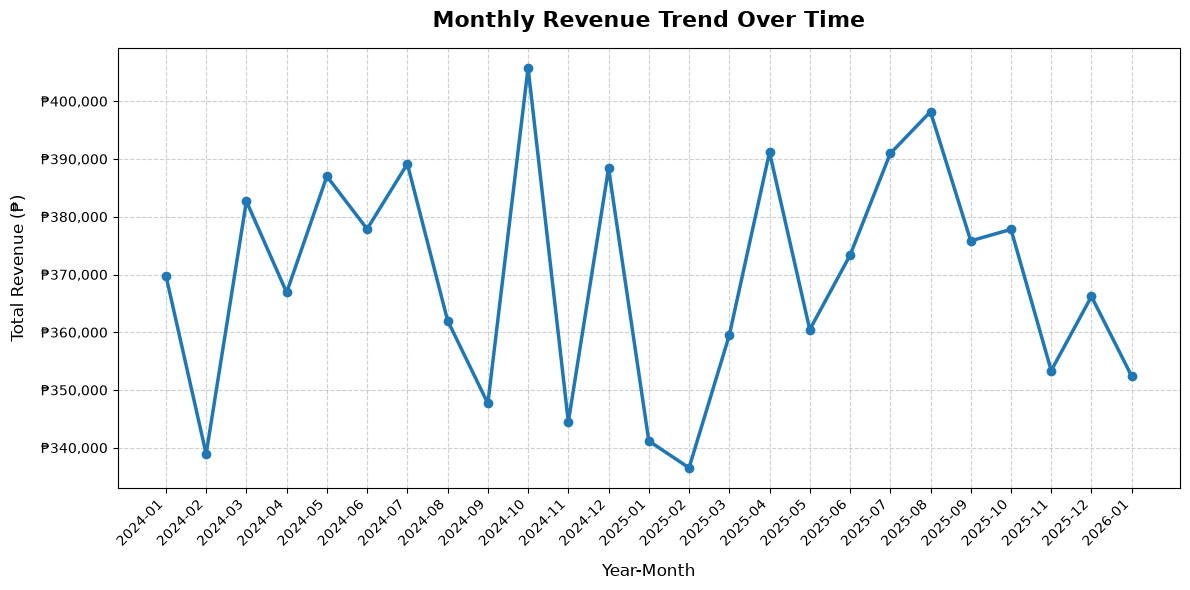

In [53]:
monthly_revenue_trend['period'] = (
    monthly_revenue_trend['year'].astype(str) + '-' + 
    monthly_revenue_trend['month'].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue_trend['period'], 
    monthly_revenue_trend['total_revenue'], 
    marker='o', 
    color='#1f77b4', 
    linewidth=2.5, 
    markersize=6,
    label='Total Revenue'
)

plt.title('Monthly Revenue Trend Over Time', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Year-Month', fontsize=12, labelpad=10)
plt.ylabel('Total Revenue (₱)', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right')

formatter = ticker.FuncFormatter(lambda x, pos: f'₱{x:,.0f}')
plt.gca().yaxis.set_major_formatter(formatter)

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.savefig('monthly_revenue_trend.png', dpi=300, bbox_inches='tight')
plt.show()

#### Revenue by Product

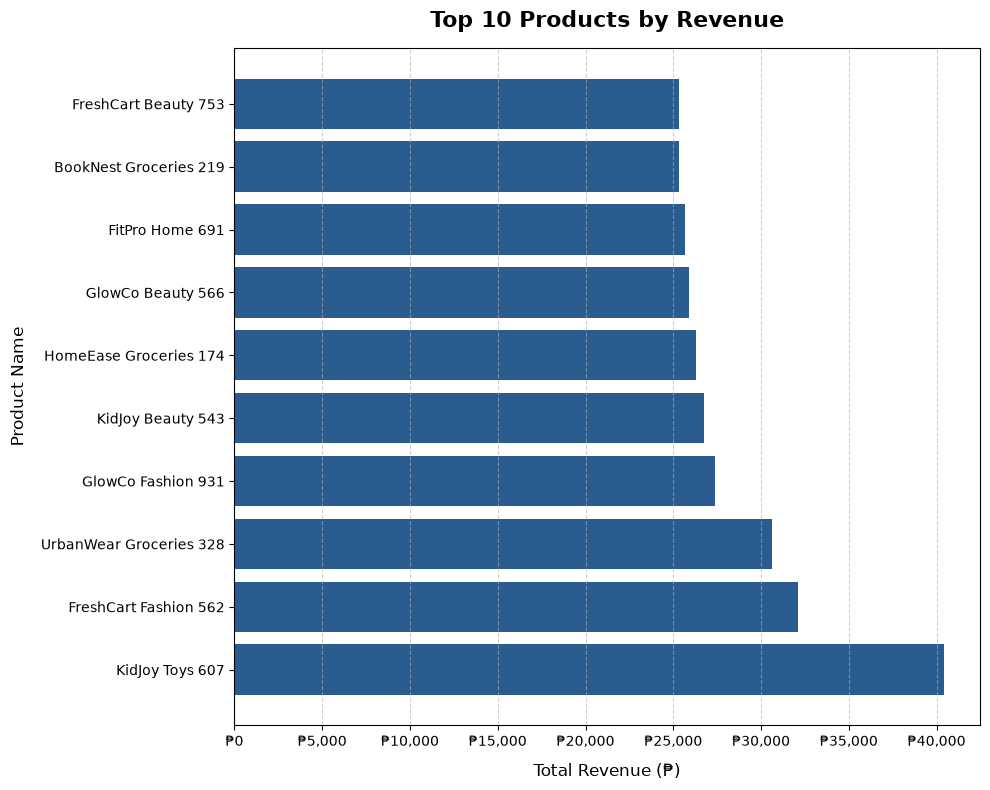

In [54]:
plt.figure(figsize=(10, 8))

plt.barh(top_10_products['product_name'], top_10_products['total_revenue'], color='#2b5c8f')

plt.title('Top 10 Products by Revenue', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Total Revenue (₱)', fontsize=12, labelpad=10)
plt.ylabel('Product Name', fontsize=12, labelpad=10)

# Format x-axis to display in Philippine Pesos with commas
formatter = ticker.FuncFormatter(lambda x, pos: f'₱{x:,.0f}')
plt.gca().xaxis.set_major_formatter(formatter)

# Add gridlines and clean layout
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Save as PNG and display
plt.savefig('top_products_by_revenue.png', dpi=300, bbox_inches='tight')
plt.show()

#### Revenue by City

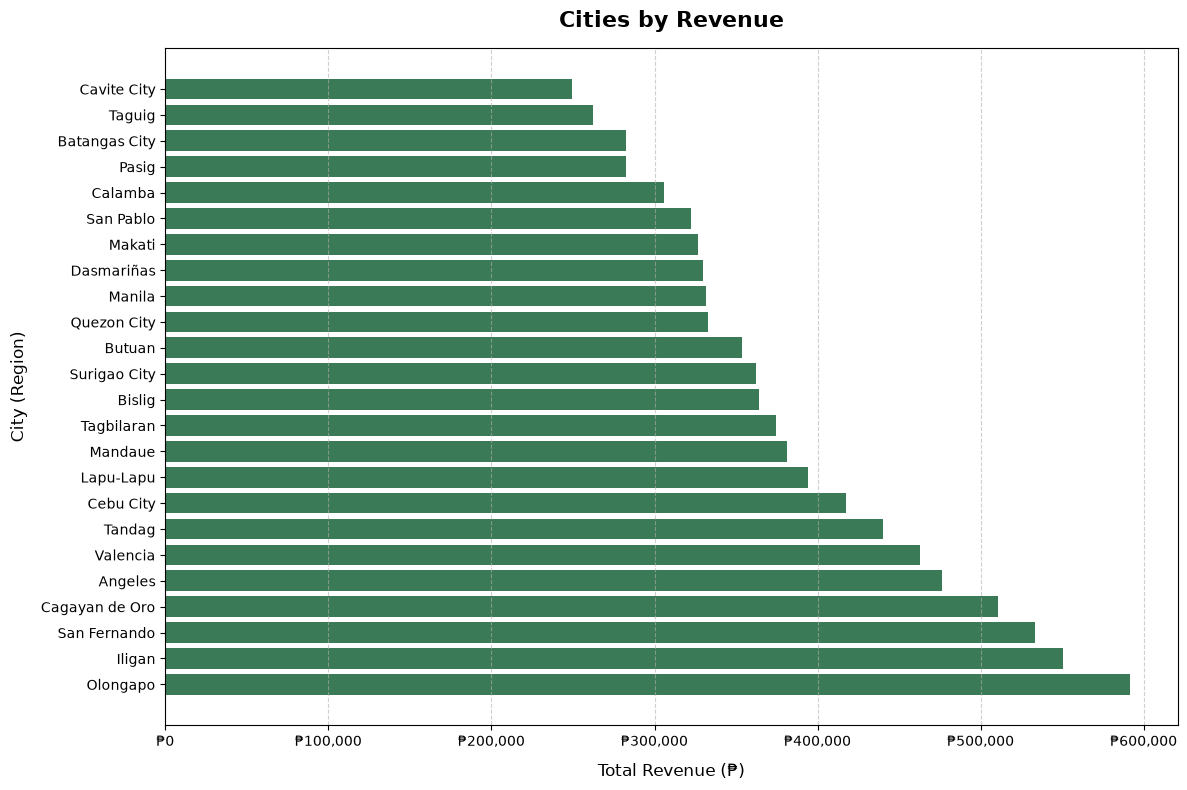

In [55]:
plt.figure(figsize=(12, 8))

# 3. Plot the horizontal bar chart
plt.barh(revenue_by_region_city['city'], revenue_by_region_city['total_revenue'], color='#3b7a57')

# 4. Customize titles and axes labels
plt.title('Cities by Revenue', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Total Revenue (₱)', fontsize=12, labelpad=10)
plt.ylabel('City (Region)', fontsize=12, labelpad=10)

# Format x-axis to display in Philippine Pesos with commas
formatter = ticker.FuncFormatter(lambda x, pos: f'₱{x:,.0f}')
plt.gca().xaxis.set_major_formatter(formatter)

# Add gridlines and clean layout
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Save as PNG and display
plt.savefig('revenue_by_region_city.png', dpi=300, bbox_inches='tight')
plt.show()

#### Revenue by Category

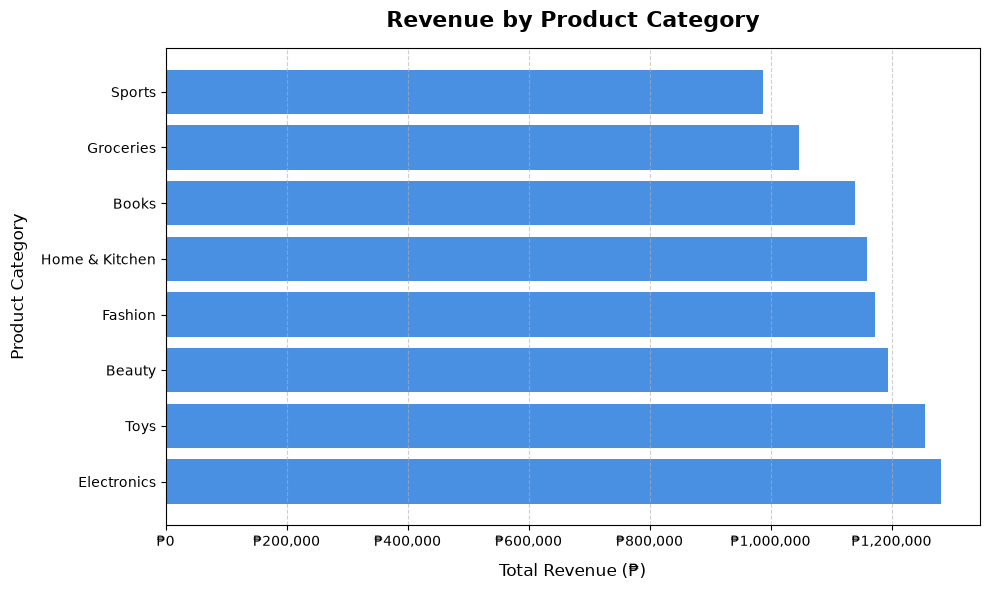

In [56]:
plt.figure(figsize=(10, 6))

plt.barh(revenue_by_category['category'], revenue_by_category['total_revenue'], color='#4a90e2')

plt.title('Revenue by Product Category', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Total Revenue (₱)', fontsize=12, labelpad=10)
plt.ylabel('Product Category', fontsize=12, labelpad=10)

formatter = ticker.FuncFormatter(lambda x, pos: f'₱{x:,.0f}')
plt.gca().xaxis.set_major_formatter(formatter)

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.savefig('revenue_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

#### Customer Spend Distribution Histogram

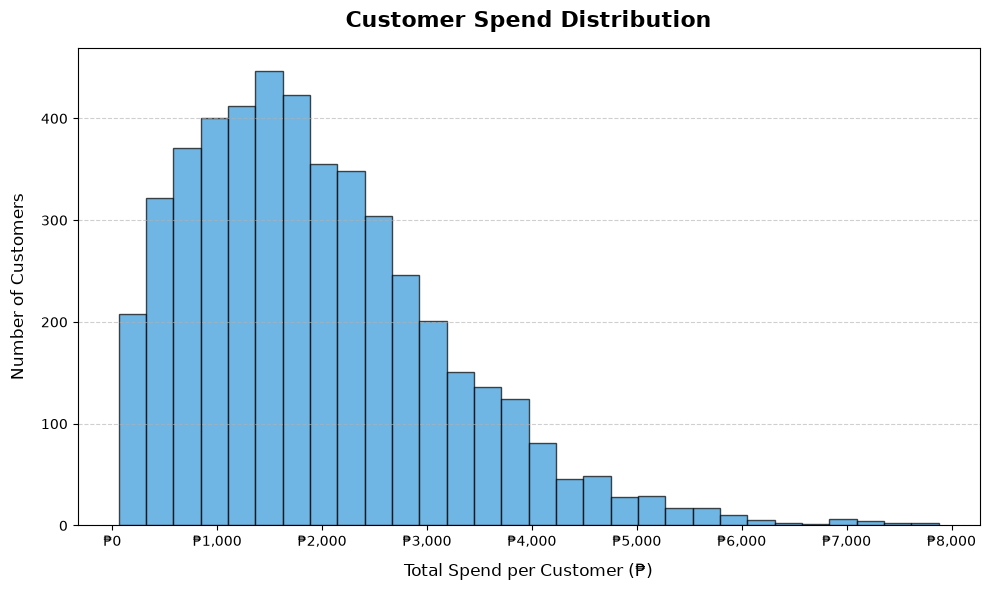

In [57]:
customer_spend = fact_sales.groupby('customer_id')['total_revenue'].sum().reset_index()

# 2. Set up the figure size
plt.figure(figsize=(10, 6))

# 3. Plot the histogram
plt.hist(
    customer_spend['total_revenue'], 
    bins=30, 
    color='#3498db', 
    edgecolor='black', 
    alpha=0.7
)

# 4. Customize titles and axes labels
plt.title('Customer Spend Distribution', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Total Spend per Customer (₱)', fontsize=12, labelpad=10)
plt.ylabel('Number of Customers', fontsize=12, labelpad=10)

# Format x-axis to display in Philippine Pesos with commas
formatter = ticker.FuncFormatter(lambda x, pos: f'₱{x:,.0f}')
plt.gca().xaxis.set_major_formatter(formatter)

# Add gridlines and clean layout
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Save as PNG and display
plt.savefig('customer_spend_histogram.png', dpi=300, bbox_inches='tight')
plt.show()